<a href="https://colab.research.google.com/github/Jorgellamocca/S2S-PER/blob/main/APS-ECMWF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q dynamical-catalog

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.6/815.6 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.3 MB/s eta 0:00:00


ECMWF IFS ENS | ANTICICLÓN DEL PACÍFICO SUR

Catálogo abierto correctamente

DIMENSIONES:
Frozen({'init_time': 297, 'lead_time': 47, 'ensemble_member': 101, 'latitude': 121, 'longitude': 240})

VERIFICACIÓN DE INICIALIZACIONES
2026-10-24 00 UTC | Días válidos: 46/46

INICIALIZACIÓN SELECCIONADA:
2026-10-24 00:00:00
Horizonte: 46 días
Miembros: 101

Longitud seleccionada: 90.0°O

Calculando promedio del ensamble...
Promedio calculado correctamente.

DIAGNÓSTICO DE FORTALECIMIENTO DEL APS


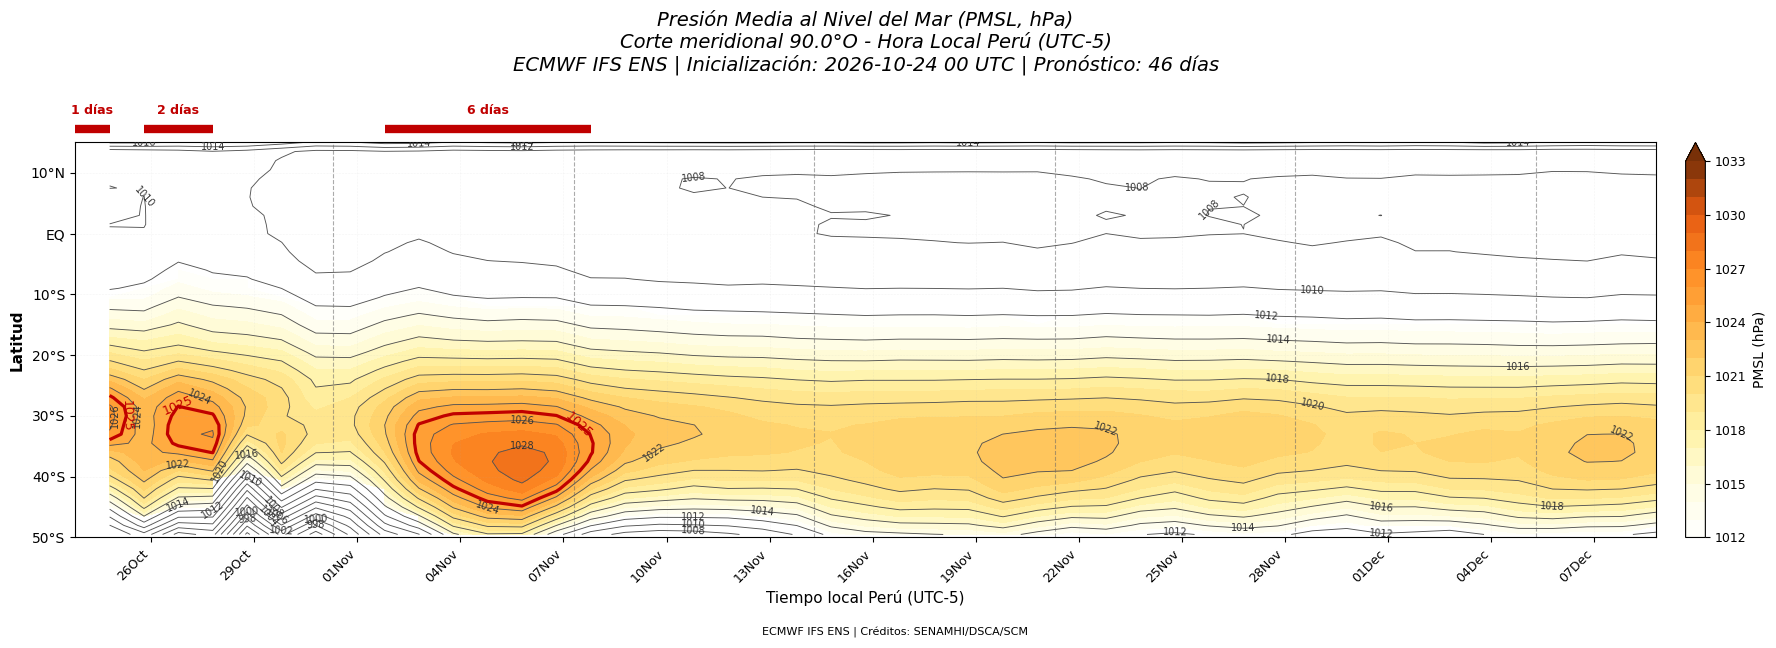


ECMWF IFS ENS | PERSISTENCIA DEL APS
Inicialización: 2026-10-24 00:00:00
Miembros: 101
Horizonte: 46 días
Longitud: -90.0
Umbral: 1025.0 hPa
Franja: 40°S - 25°S
Criterio: maximo

PERIODOS CON PMSL >= 1025 hPa
--------------------------------------------------------------------------------
Evento 01 | 23/10/2026 19:00 - 24/10/2026 19:00 | 1 días | PMSL máxima: 1026.5 hPa
Evento 02 | 25/10/2026 19:00 - 27/10/2026 19:00 | 2 días | PMSL máxima: 1026.1 hPa
Evento 03 | 01/11/2026 19:00 - 07/11/2026 19:00 | 6 días | PMSL máxima: 1028.6 hPa

PROCESAMIENTO COMPLETADO


In [2]:
# -*- coding: utf-8 -*-

# ================================================================
# ECMWF IFS ENS | ANTICICLÓN DEL PACÍFICO SUR
# HOVMÖLLER DE PRESIÓN MEDIA AL NIVEL DEL MAR
#
# Corte meridional: 90°O
# Pronóstico: 46 días
# Media del ensamble (101 miembros)
# Resolución: 1.5°
#
# Barra de colores: 1012 a 1033 hPa
# Isobaras: cada 2 hPa
# Contorno destacado: 1025 hPa
# Persistencia: 25°S a 40°S
# Fechas en hora local Perú (UTC-5)
#
# SIN GUARDAR ARCHIVOS
# Créditos: SENAMHI/DSCA/SCM
# ================================================================

# ================================================================
# 0. INSTALACIÓN
# ================================================================

%pip install -q dynamical-catalog netcdf4

# ================================================================
# 1. LIBRERÍAS
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.transforms as transforms

import dynamical_catalog

# ================================================================
# 2. CONFIGURACIÓN
# ================================================================

CATALOGO = (
    "ecmwf-ifs-ens-forecast-46-day-daily-1-5-degree"
)

VARIABLE = "pressure_reduced_to_mean_sea_level"

# Corte meridional
LONGITUD_CORTE = -90.0

# Dominio latitudinal
LAT_MIN = -50
LAT_MAX = 15

# Pronóstico
DIA_INICIAL = 1
N_DIAS = 46

# Barra de colores
P_MIN = 1012
P_MAX = 1033

# Isobaras cada 2 hPa
ISOBARAS = np.arange(960, 1060, 2)

NIVELES_COLOR = np.arange(
    P_MIN,
    P_MAX + 1,
    1
)

# Umbral de fortalecimiento del APS
UMBRAL_APS = 1025.0

# Franja para evaluar persistencia
LAT_APS_MIN = -40.0
LAT_APS_MAX = -25.0

# Criterio:
# "maximo"   = al menos una latitud >= 1025 hPa
# "promedio" = promedio de toda la franja >= 1025 hPa

CRITERIO_APS = "maximo"

# ================================================================
# 3. ABRIR CATÁLOGO ECMWF
# ================================================================

print("=" * 80)
print("ECMWF IFS ENS | ANTICICLÓN DEL PACÍFICO SUR")
print("=" * 80)

ds = dynamical_catalog.open(
    CATALOGO,
    chunks=None
)

if VARIABLE not in ds.data_vars:
    raise KeyError(
        f"No se encontró la variable: {VARIABLE}"
    )

print("\nCatálogo abierto correctamente")

print("\nDIMENSIONES:")
print(ds.sizes)

# ================================================================
# 4. IDENTIFICAR LONGITUD
# ================================================================

if float(ds.longitude.max()) > 180:

    LON_BUSQUEDA = LONGITUD_CORTE % 360

else:

    LON_BUSQUEDA = LONGITUD_CORTE

# ================================================================
# 5. VERIFICAR INICIALIZACIONES CON 46 DÍAS
# ================================================================

print("\n" + "=" * 80)
print("VERIFICACIÓN DE INICIALIZACIONES")
print("=" * 80)

lead_esperado = pd.timedelta_range(
    start=pd.Timedelta(days=DIA_INICIAL),
    periods=N_DIAS,
    freq="D"
)

lead_disponible = pd.to_timedelta(
    ds.lead_time.values
)

faltantes = lead_esperado.difference(
    lead_disponible
)

if len(faltantes) > 0:

    raise RuntimeError(
        "El catálogo no contiene todos los "
        f"plazos diarios solicitados: {faltantes}"
    )

INIT_TIME = None

# Verificación en un punto de referencia
# dentro del dominio del APS

for fecha in ds.init_time.values[::-1]:

    prueba = ds[VARIABLE].sel(
        init_time=fecha,
        longitude=LON_BUSQUEDA,
        latitude=-30.0,
        method="nearest"
    )

    if "ensemble_member" in prueba.dims:

        prueba = prueba.isel(
            ensemble_member=0
        )

    prueba = prueba.sel(
        lead_time=lead_esperado
    ).compute()

    validos = np.isfinite(
        prueba.values
    )

    n_validos = int(
        np.count_nonzero(validos)
    )

    print(
        f"{pd.Timestamp(fecha):%Y-%m-%d %H UTC} | "
        f"Días válidos: {n_validos}/{N_DIAS}"
    )

    if n_validos == N_DIAS:

        INIT_TIME = fecha

        break

if INIT_TIME is None:

    raise RuntimeError(
        "No se encontró una inicialización "
        "con 46 días válidos."
    )

INIT = pd.Timestamp(INIT_TIME)

N_MIEMBROS = ds.sizes["ensemble_member"]

print("\nINICIALIZACIÓN SELECCIONADA:")
print(INIT)
print("Horizonte:", N_DIAS, "días")
print("Miembros:", N_MIEMBROS)

# ================================================================
# 6. SELECCIONAR VARIABLE
# ================================================================

p = ds[VARIABLE].sel(
    init_time=INIT_TIME
)

# Convertir longitud 0-360 a -180/180

if float(p.longitude.max()) > 180:

    p = p.assign_coords(
        longitude=(
            (p.longitude + 180) % 360
        ) - 180
    )

p = p.sortby("longitude")
p = p.sortby("latitude")

# ================================================================
# 7. CORTE MERIDIONAL
# ================================================================

p = p.sel(
    longitude=LONGITUD_CORTE,
    method="nearest"
)

LONGITUD_REAL = float(
    p.longitude.values
)

p = p.sel(
    latitude=slice(
        LAT_MIN,
        LAT_MAX
    )
)

print(
    "\nLongitud seleccionada:",
    f"{abs(LONGITUD_REAL):.1f}°O"
)

# ================================================================
# 8. SELECCIONAR 46 DÍAS
# ================================================================

p = p.sel(
    lead_time=lead_esperado
)

# ================================================================
# 9. PROMEDIO DEL ENSAMBLE
# ================================================================

print("\nCalculando promedio del ensamble...")

p_media = p.mean(
    dim="ensemble_member",
    skipna=True
)

# Convertir Pa a hPa

unidades = p.attrs.get(
    "units", ""
).strip().lower()

if unidades in [
    "pa",
    "pascal",
    "pascals"
]:

    p_media = p_media / 100.0

elif unidades in [
    "hpa",
    "mbar",
    "millibar"
]:

    pass

else:

    raise ValueError(
        f"Unidad de presión desconocida: {unidades}"
    )

p_media = p_media.transpose(
    "latitude",
    "lead_time"
).load()

print("Promedio calculado correctamente.")

# ================================================================
# 10. FECHAS
# ================================================================

fechas_utc = pd.DatetimeIndex(
    INIT + pd.to_timedelta(
        p_media.lead_time.values
    )
)

# Hora local Perú UTC-5

fechas_local = (
    fechas_utc -
    pd.Timedelta(hours=5)
)

latitudes = p_media.latitude.values

P = p_media.values

# ================================================================
# 11. IDENTIFICAR PMSL >= 1025 hPa
# ================================================================

print("\n" + "=" * 80)
print("DIAGNÓSTICO DE FORTALECIMIENTO DEL APS")
print("=" * 80)

mask_lat = (
    (latitudes >= LAT_APS_MIN) &
    (latitudes <= LAT_APS_MAX)
)

if not np.any(mask_lat):

    raise RuntimeError(
        "No existen latitudes dentro "
        "de la franja del APS."
    )

P_APS = P[mask_lat, :]

# Máxima presión diaria dentro de la franja

if CRITERIO_APS == "maximo":

    PMSL_APS = np.nanmax(
        P_APS,
        axis=0
    )

elif CRITERIO_APS == "promedio":

    PMSL_APS = np.nanmean(
        P_APS,
        axis=0
    )

else:

    raise ValueError(
        "CRITERIO_APS debe ser "
        "'maximo' o 'promedio'."
    )

supera_umbral = (
    np.isfinite(PMSL_APS) &
    (PMSL_APS >= UMBRAL_APS)
)

# ================================================================
# 12. IDENTIFICAR PERIODOS CONSECUTIVOS
# ================================================================

periodos = []

inicio_evento = None

for i, activo in enumerate(supera_umbral):

    if activo and inicio_evento is None:

        inicio_evento = i

    if inicio_evento is not None:

        if (not activo) or (
            i == len(supera_umbral) - 1
        ):

            fin_evento = (
                i if activo else i - 1
            )

            periodos.append(
                (inicio_evento, fin_evento)
            )

            inicio_evento = None

# ================================================================
# 13. PALETA ORIGINAL ECMWF 1012-1033 hPa
# ================================================================

COLORES = [
    (1012, "#FFFFFF"),
    (1015, "#FFFDE0"),
    (1018, "#FFF2A6"),
    (1021, "#FFDA75"),
    (1024, "#FFB347"),
    (1027, "#FF8C24"),
    (1030, "#E65C12"),
    (1033, "#783008")
]

CMAP = mcolors.LinearSegmentedColormap.from_list(
    "PMSL_APS",
    [
        (
            (valor - P_MIN) / (P_MAX - P_MIN),
            color
        )
        for valor, color in COLORES
    ],
    N=256
)

CMAP.set_over("#783008")
CMAP.set_under("#FFFFFF")

NORM = mcolors.Normalize(
    vmin=P_MIN,
    vmax=P_MAX
)

# ================================================================
# 14. FIGURA
# ================================================================

fig, ax = plt.subplots(
    figsize=(18, 7),
    facecolor="white"
)

# ------------------------------------------------------------
# SOMBREADO DE PRESIÓN
# ------------------------------------------------------------

P_SOMBREADO = np.ma.masked_less(
    P,
    P_MIN
)

cf = ax.contourf(
    fechas_local,
    latitudes,
    P_SOMBREADO,
    levels=NIVELES_COLOR,
    cmap=CMAP,
    norm=NORM,
    extend="max"
)

# ------------------------------------------------------------
# ISOBARAS CADA 2 hPa
# ------------------------------------------------------------

cs = ax.contour(
    fechas_local,
    latitudes,
    P,
    levels=ISOBARAS,
    colors="#555555",
    linewidths=0.65
)

etiquetas = ax.clabel(
    cs,
    inline=False,
    fontsize=7,
    fmt="%d",
    colors="#333333"
)

# Eliminar fondos y bordes blancos

for etiqueta in etiquetas:

    etiqueta.set_path_effects([])
    etiqueta.set_bbox(None)

# ================================================================
# 15. DESTACAR ISOBARA DE 1025 hPa
# ================================================================

if (
    np.nanmin(P) <= UMBRAL_APS <= np.nanmax(P)
):

    cs_1025 = ax.contour(
        fechas_local,
        latitudes,
        P,
        levels=[UMBRAL_APS],
        colors="#C00000",
        linewidths=2.3,
        zorder=5
    )

    etiquetas_1025 = ax.clabel(
        cs_1025,
        fmt={UMBRAL_APS: "1025"},
        inline=False,
        fontsize=9,
        colors="#C00000"
    )

    for etiqueta in etiquetas_1025:

        etiqueta.set_path_effects([])
        etiqueta.set_bbox(None)

# ================================================================
# 16. BARRAS SUPERIORES DE PERSISTENCIA
# ================================================================

trans = transforms.blended_transform_factory(
    ax.transData,
    ax.transAxes
)

for i0, i1 in periodos:

    # Cada valor diario corresponde al plazo
    # de +24, +48, ..., +1104 horas.
    # Se representa el intervalo de 24 h
    # que finaliza en dicho plazo.

    fecha_inicio = (
        fechas_local[i0] -
        pd.Timedelta(days=1)
    )

    fecha_fin = fechas_local[i1]

    duracion = i1 - i0 + 1

    fecha_centro = (
        fecha_inicio +
        (fecha_fin - fecha_inicio) / 2
    )

    # Barra roja

    ax.plot(
        [fecha_inicio, fecha_fin],
        [1.035, 1.035],
        color="#C00000",
        linewidth=6,
        solid_capstyle="butt",
        transform=trans,
        clip_on=False
    )

    # Etiqueta de duración

    ax.text(
        fecha_centro,
        1.065,
        f"{duracion} días",
        color="#C00000",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="bottom",
        transform=trans,
        clip_on=False
    )

# ================================================================
# 17. SEPARACIÓN DE SEMANAS
# ================================================================

for semana in range(1, 7):

    indice = semana * 7

    if indice >= len(fechas_local):
        break

    fecha_separacion = (
        fechas_local[indice - 1] +
        (
            fechas_local[indice] -
            fechas_local[indice - 1]
        ) / 2
    )

    ax.axvline(
        fecha_separacion,
        color="#666666",
        linestyle="--",
        linewidth=0.8,
        alpha=0.55
    )

# ================================================================
# 18. EJES
# ================================================================

ax.set_ylim(
    LAT_MIN,
    LAT_MAX
)

ax.set_yticks([
    -50, -40, -30, -20, -10, 0, 10
])

ax.set_yticklabels([
    "50°S",
    "40°S",
    "30°S",
    "20°S",
    "10°S",
    "EQ",
    "10°N"
])

ax.set_ylabel(
    "Latitud",
    fontsize=11,
    fontweight="bold"
)

ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d%b")
)

ax.tick_params(
    axis="x",
    labelsize=9
)

ax.tick_params(
    axis="y",
    labelsize=10
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

ax.grid(
    linestyle=":",
    linewidth=0.4,
    alpha=0.25
)

ax.set_xlabel(
    "Tiempo local Perú (UTC-5)",
    fontsize=11
)

ax.set_xlim(
    fechas_local[0] - pd.Timedelta(days=1),
    fechas_local[-1]
)

# ================================================================
# 19. TÍTULO
# ================================================================

titulo = (
    "Presión Media al Nivel del Mar (PMSL, hPa)\n"
    f"Corte meridional {abs(LONGITUD_REAL):.1f}°O "
    "- Hora Local Perú (UTC-5)\n"
    f"ECMWF IFS ENS | Inicialización: "
    f"{INIT:%Y-%m-%d %H UTC} | "
    f"Pronóstico: {N_DIAS} días"
)

ax.set_title(
    titulo,
    fontsize=14,
    fontstyle="italic",
    pad=52
)

# ================================================================
# 20. BARRA DE COLORES
# ================================================================

cbar = fig.colorbar(
    cf,
    ax=ax,
    orientation="vertical",
    pad=0.018,
    fraction=0.025,
    ticks=np.arange(1012, 1034, 3)
)

cbar.set_label(
    "PMSL (hPa)",
    fontsize=10
)

cbar.ax.tick_params(
    labelsize=9
)

# ================================================================
# 21. CRÉDITOS
# ================================================================

fig.text(
    0.5,
    0.015,
    "ECMWF IFS ENS | Créditos: SENAMHI/DSCA/SCM",
    ha="center",
    fontsize=8
)

plt.tight_layout(
    rect=[0, 0.035, 1, 0.93]
)

plt.show()

# ================================================================
# 22. RESUMEN DE PERSISTENCIA
# ================================================================

print("\n" + "=" * 80)
print("ECMWF IFS ENS | PERSISTENCIA DEL APS")
print("=" * 80)

print("Inicialización:", INIT)
print("Miembros:", N_MIEMBROS)
print("Horizonte:", N_DIAS, "días")
print("Longitud:", LONGITUD_REAL)
print("Umbral:", UMBRAL_APS, "hPa")
print("Franja:", "40°S - 25°S")
print("Criterio:", CRITERIO_APS)

print("\nPERIODOS CON PMSL >= 1025 hPa")
print("-" * 80)

if periodos:

    for n, (i0, i1) in enumerate(
        periodos, 1
    ):

        fecha_inicio = (
            fechas_local[i0] -
            pd.Timedelta(days=1)
        )

        fecha_fin = fechas_local[i1]

        duracion = i1 - i0 + 1

        pmax = np.nanmax(
            PMSL_APS[i0:i1 + 1]
        )

        print(
            f"Evento {n:02d} | "
            f"{fecha_inicio:%d/%m/%Y %H:%M} - "
            f"{fecha_fin:%d/%m/%Y %H:%M} | "
            f"{duracion} días | "
            f"PMSL máxima: {pmax:.1f} hPa"
        )

else:

    print(
        "No se identificaron periodos "
        "con PMSL >= 1025 hPa."
    )

print("\n" + "=" * 80)
print("PROCESAMIENTO COMPLETADO")
print("=" * 80)